# Ước lượng giá đồng cùng thời điểm với Top 4 `spearman_price` và 7 phương pháp

Bám theo cách căn biến của paper: các giá đóng cửa ngoại sinh tại ngày `t` được dùng để ước lượng giá đóng cửa Copper tại chính ngày `t`. Các phương pháp: Naive Persistence, LSTM, Paper SA-LSTM, Re-optimized SA-LSTM, GRU, CNN1D-LSTM và SA-GRU.

Chỉ tiêu chính: **MSE trên thang MinMax** và **thời gian huấn luyện**. Đây là **contemporaneous estimation/nowcasting**, không phải dự báo `t+1`. CSV hợp nhất dùng cột `Price` (close/settlement) của Investing. Scaler chỉ fit trên train; SA chỉ dùng validation.

## 1. Môi trường và cấu hình

In [1]:
from pathlib import Path
import gc, json, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf

SEED = 42
TARGET = 'Copper'
FEATURES = ['Aluminium', 'Tin', 'Silver', 'Gold']
LOOKBACK = 22
RATIOS = [0.90, 0.925, 0.95]
MODE = 'FULL_RESEARCH_MODE'  # Chạy QUICK_MODE để smoke test; PAPER mode rất tốn GPU
MODE_CONFIG = {
    'QUICK_MODE': {'epochs': 3, 'patience': 2, 'sa_epochs': 2, 'sa_evaluations': 4, 'early_stopping': True},
    'FULL_RESEARCH_MODE': {'epochs': 100, 'patience': 15, 'sa_epochs': 20, 'sa_evaluations': 100, 'early_stopping': True},
    # Paper báo 100 epoch chính, 50 iterations/process và 650 scenarios.
    # Việc ánh xạ 50 iterations thành 50 epoch/candidate là giả định tái lập được ghi rõ.
    'PAPER_REPRODUCTION_MODE': {'epochs': 100, 'patience': None, 'sa_epochs': 50, 'sa_evaluations': 650, 'early_stopping': False},
}
BATCH_SIZE = 64
cfg = MODE_CONFIG[MODE]
tf.keras.utils.set_random_seed(SEED)
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
OUTPUT_DIR = Path('/kaggle/working/copper_contemporaneous_paper_sa') if Path('/kaggle/working').exists() else Path('copper_contemporaneous_paper_sa')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))
print('Mode:', MODE, '| Output:', OUTPUT_DIR.resolve())

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Mode: FULL_RESEARCH_MODE | Output: /kaggle/working/copper_contemporaneous_paper_sa


### Phạm vi tái lập paper

- Paper dùng các chuỗi **Normalized Closed Price**. Dataset này dùng cột `Price` (close/settlement) của Investing, không dùng `Open`.
- Căn biến theo cùng ngày: bốn biến ngoại sinh tại `t` → Copper tại `t`. Vì vậy đây là ước lượng cùng thời điểm, không phải forecast `t+1`.
- Paper SA-LSTM là cấu hình công bố 39/111, LR `5e-5`. Re-optimized SA-LSTM mới thực sự chạy lại SA.
- SA dùng T0=1, Tf=0.1, cooling=0.95 và ngân sách 650 scenarios. Paper không công bố đầy đủ bounds, proposal width và cách phân bổ scenarios theo mức nhiệt; notebook ghi rõ các giả định này.
- Công thức Metropolis in trong paper có dấu làm xác suất nghiệm xấu vượt 1; notebook dùng dấu âm chuẩn. SA-GRU là phần mở rộng mới, không phải mô hình của paper.

## 2. Nạp và kiểm tra dataset

In [2]:


def load_dataset(path):
    raw = pd.read_csv(path)
    required = ['Date', TARGET] + FEATURES
    missing = [c for c in required if c not in raw.columns]
    if missing:
        raise ValueError(f'Thiếu cột: {missing}')
    data = raw[required].copy()
    data['Date'] = pd.to_datetime(data['Date'], errors='coerce')
    for col in [TARGET] + FEATURES:
        data[col] = pd.to_numeric(data[col], errors='coerce')
    quality = pd.DataFrame({
        'column': data.columns,
        'missing': data.isna().sum().values,
        'dtype': data.dtypes.astype(str).values,
    })
    if data['Date'].duplicated().any():
        raise ValueError('Dataset có Date trùng lặp')
    data = data.dropna().sort_values('Date').set_index('Date')
    if not data.index.is_monotonic_increasing or len(data) <= LOOKBACK + 100:
        raise ValueError('Dataset không đủ dài hoặc chưa sắp xếp')
    return data, quality

DATA_PATH = '/kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv'
data, quality = load_dataset(DATA_PATH)
print('Dataset:', DATA_PATH)
print(f'{len(data):,} dòng | {data.index.min().date()} -> {data.index.max().date()}')
display(quality)
display(data.head())

Dataset: /kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv
2,710 dòng | 2016-01-13 -> 2026-11-13


,column,missing,dtype
0,Date,0,datetime64[ns]
1,Copper,0,float64
2,Aluminium,0,float64
3,Tin,0,float64
4,Silver,0,float64
5,Gold,0,float64


,Copper,Aluminium,Tin,Silver,Gold
Date,,,,,
2016-01-13,1.9560,1462.5,13305.0,14.156,1087.1
2016-01-14,1.9760,1483.0,13260.0,13.748,1073.6
2016-01-15,1.9435,1473.0,13205.0,13.896,1090.7
2016-01-19,1.9775,1481.0,13225.0,14.121,1090.7
2016-01-20,1.9595,1469.0,13390.0,14.160,1106.2


## 3. Chia thời gian và chuẩn hóa chống leakage

In [3]:
def split_boundaries(n, ratio, validation_fraction=0.10):
    test_start = int(n * ratio)
    val_start = int(test_start * (1 - validation_fraction))
    if not LOOKBACK < val_start < test_start < n:
        raise ValueError('Split không hợp lệ')
    return val_start, test_start

def make_windows(x, y, dates, start, end):
    # Cùng thời điểm như paper: cửa sổ ngoại sinh chứa cả ngày target t.
    # X[t-21 ... t] -> Copper(t); không có Copper(t) trong input.
    X = np.stack([x[t-LOOKBACK+1:t+1] for t in range(start, end)]).astype('float32')
    Y = y[start:end].astype('float32')
    D = dates[start:end]
    return X, Y, D

def prepare_split(frame, ratio):
    val_start, test_start = split_boundaries(len(frame), ratio)
    train_frame = frame.iloc[:val_start]
    x_scaler = MinMaxScaler().fit(train_frame[FEATURES])
    y_scaler = MinMaxScaler().fit(train_frame[[TARGET]])
    x = x_scaler.transform(frame[FEATURES]).astype('float32')
    y = y_scaler.transform(frame[[TARGET]]).ravel().astype('float32')
    previous = frame[TARGET].shift(1).to_numpy()
    previous_scaled = y_scaler.transform(previous.reshape(-1, 1)).ravel().astype('float32')
    ctx = {
        'train': make_windows(x, y, frame.index, LOOKBACK, val_start),
        'val': make_windows(x, y, frame.index, val_start, test_start),
        'test': make_windows(x, y, frame.index, test_start, len(frame)),
        'val_previous': previous_scaled[val_start:test_start],
        'test_previous': previous_scaled[test_start:],
        'x_scaler': x_scaler, 'y_scaler': y_scaler,
        'val_start': val_start, 'test_start': test_start, 'ratio': ratio,
    }
    assert ctx['train'][2].max() < ctx['val'][2].min() < ctx['test'][2].min()
    return ctx

split_rows = []
for ratio in RATIOS:
    a, b = split_boundaries(len(data), ratio)
    split_rows += [
        {'ratio': ratio, 'segment': 'train', 'samples': a-LOOKBACK, 'first': data.index[LOOKBACK], 'last': data.index[a-1]},
        {'ratio': ratio, 'segment': 'validation', 'samples': b-a, 'first': data.index[a], 'last': data.index[b-1]},
        {'ratio': ratio, 'segment': 'test', 'samples': len(data)-b, 'first': data.index[b], 'last': data.index[-1]},
    ]
split_summary = pd.DataFrame(split_rows)
split_summary.to_csv(OUTPUT_DIR / 'split_summary.csv', index=False)
display(split_summary)
primary_train_end, _ = split_boundaries(len(data), RATIOS[0])
train_corr = data.iloc[:primary_train_end][[TARGET] + FEATURES].corr(method='spearman')
display(train_corr[TARGET].sort_values(ascending=False).to_frame('train_only_spearman_price'))

,ratio,segment,samples,first,last
0,0.900,train,2173,2016-02-16,2024-11-12
1,0.900,validation,244,2024-11-13,2025-10-28
2,0.900,test,271,2025-10-29,2026-11-13
3,0.925,train,2233,2016-02-16,2025-02-10
4,0.925,validation,251,2025-02-11,2026-01-29
5,0.925,test,204,2026-01-30,2026-11-13
6,0.950,train,2294,2016-02-16,2025-05-08
7,0.950,validation,258,2025-05-09,2026-05-06
8,0.950,test,136,2026-05-07,2026-11-13


,train_only_spearman_price
Copper,1.000000
Aluminium,0.927934
Tin,0.882912
Gold,0.742536
Silver,0.742385


## 4. Naive Persistence — baseline riêng

In [4]:
def predict_naive_persistence(ctx):
    """Dự báo Copper(t) = Copper(t-1), không huấn luyện."""
    return {
        'val_prediction': ctx['val_previous'].copy(),
        'test_prediction': ctx['test_previous'].copy(),
        'history': None, 'epochs_run': 0, 'train_seconds': 0.0,
    }

## 5. LSTM — cell định nghĩa cấu trúc riêng

In [5]:
def build_lstm(input_shape, hp=None):
    model = tf.keras.Sequential(name='LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(64, return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(32))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model

## 6. Paper SA-LSTM — cấu hình tác giả công bố

In [6]:
PAPER_SA_LSTM_HP = {'units_1': 39, 'units_2': 111, 'learning_rate': 5e-5}

def build_paper_sa_lstm(input_shape, hp=None):
    # Hai lớp LSTM và bộ 39/111, LR=5e-5 được paper công bố.
    # Dense ReLU, output linear và Adam là các giả định triển khai đã được ghi nhận.
    model = tf.keras.Sequential(name='Paper_SA_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(39, return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(111))
    model.add(tf.keras.layers.Dense(32, activation='relu'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(5e-5), loss='mse')
    return model

## 7. Re-optimized SA-LSTM — SA chạy lại trên dataset mới

In [7]:
def build_reoptimized_sa_lstm(input_shape, hp):
    model = tf.keras.Sequential(name='Reoptimized_SA_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(int(hp['units_1']), return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(int(hp['units_2'])))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    optimizer = tf.keras.optimizers.Adam(float(hp['learning_rate']))
    model.compile(optimizer=optimizer, loss='mse')
    return model

## 8. GRU — cell định nghĩa cấu trúc riêng

In [8]:
def build_gru(input_shape, hp=None):
    model = tf.keras.Sequential(name='GRU')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.GRU(64, return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.GRU(32))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model

## 9. CNN1D–LSTM — cell định nghĩa cấu trúc riêng

In [9]:
def build_cnn1d_lstm(input_shape, hp=None):
    model = tf.keras.Sequential(name='CNN1D_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.Conv1D(filters=32, kernel_size=3, padding='causal', activation='relu'))
    model.add(tf.keras.layers.MaxPooling1D(pool_size=2))
    model.add(tf.keras.layers.LSTM(48, return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(24))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model

## 10. SA-GRU — cấu trúc riêng, siêu tham số do Simulated Annealing chọn

In [10]:
def build_sa_gru(input_shape, hp):
    model = tf.keras.Sequential(name='SA_GRU')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.GRU(int(hp['units_1']), return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.GRU(int(hp['units_2'])))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    optimizer = tf.keras.optimizers.Adam(float(hp['learning_rate']))
    model.compile(optimizer=optimizer, loss='mse')
    return model

## 11. Hàm huấn luyện dùng chung

In [11]:
def reset_tf(seed=SEED):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(seed)

def fit_validation_only(builder, ctx, hp, epochs):
    """SA gọi hàm này; hàm không đọc test window hoặc test label."""
    reset_tf()
    Xtr, ytr, _ = ctx['train']
    Xval, yval, _ = ctx['val']
    model = builder(Xtr.shape[1:], hp)
    start = time.perf_counter()
    callbacks = []
    if cfg['early_stopping']:
        callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)]
    history = model.fit(
        Xtr, ytr, validation_data=(Xval, yval), epochs=epochs,
        batch_size=BATCH_SIZE, shuffle=False, verbose=0, callbacks=callbacks,
    )
    pred = model.predict(Xval, verbose=0).ravel()
    score = float(mean_squared_error(yval, pred))
    seconds = time.perf_counter() - start
    del model
    reset_tf()
    return score, seconds, len(history.history['loss'])

def train_and_predict(builder, ctx, hp=None):
    reset_tf()
    Xtr, ytr, _ = ctx['train']
    Xval, yval, _ = ctx['val']
    Xte, _, _ = ctx['test']
    model = builder(Xtr.shape[1:], hp)
    callbacks = []
    if cfg['early_stopping']:
        callbacks = [tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=cfg['patience'], restore_best_weights=True
        )]
    fit_start = time.perf_counter()
    history = model.fit(
        Xtr, ytr, validation_data=(Xval, yval), epochs=cfg['epochs'],
        batch_size=BATCH_SIZE, shuffle=False, verbose=0, callbacks=callbacks,
    )
    train_seconds = time.perf_counter() - fit_start
    predict_start = time.perf_counter()
    val_pred = model.predict(Xval, verbose=0).ravel()
    test_pred = model.predict(Xte, verbose=0).ravel()
    prediction_seconds = time.perf_counter() - predict_start
    result = {
        'val_prediction': val_pred, 'test_prediction': test_pred,
        'history': history.history, 'epochs_run': len(history.history['loss']),
        'train_seconds': train_seconds,
        'prediction_seconds': prediction_seconds,
    }
    del model
    reset_tf()
    return result

## 12. Simulated Annealing theo paper, tìm riêng cho LSTM và GRU

In [12]:
PAPER_SA = {
    'initial_temperature': 1.0, 'final_temperature': 0.1, 'cooling': 0.95,
    'proposals_per_temperature': 15,  # 650 scenarios / khoảng 45 mức nhiệt
    'proposal_width': 2.0, 'units_min': 8, 'units_max': 128,
    'lr_min': 1e-6, 'lr_max': 0.005,
    'initial': {'units_1': 15, 'units_2': 30, 'learning_rate': 5e-4},
}

def _sigmoid(z):
    return 1.0 / (1.0 + math.exp(-float(np.clip(z, -30, 30))))

def _logit(p):
    p = float(np.clip(p, 1e-6, 1 - 1e-6))
    return math.log(p / (1.0 - p))

def paper_proposal(current, temperature, rng):
    # Bám Eq. 7–8: chuyển tham số sang latent coordinate, perturb theo T,
    # rồi sigmoid trở lại miền hữu hạn. Bounds/proposal_width là giả định cần thiết.
    candidate = {}
    for key in ('units_1', 'units_2', 'learning_rate'):
        if key == 'learning_rate':
            lo, hi, value = math.log(PAPER_SA['lr_min']), math.log(PAPER_SA['lr_max']), math.log(current[key])
        else:
            lo, hi, value = PAPER_SA['units_min'], PAPER_SA['units_max'], current[key]
        latent = _logit((value - lo) / (hi - lo))
        moved = latent + temperature * PAPER_SA['proposal_width'] * rng.uniform(-1.0, 1.0)
        bounded = lo + (hi - lo) * _sigmoid(moved)
        candidate[key] = float(math.exp(bounded)) if key == 'learning_rate' else int(np.clip(round(bounded), lo, hi))
    return candidate

def metropolis(delta, temperature, rng):
    # Paper in exp(+delta/T), nhưng dấu đó cho xác suất > 1 với nghiệm xấu.
    # Dùng dấu âm chuẩn của Metropolis; đây là hiệu chỉnh lỗi công thức được công bố.
    probability = 1.0 if delta <= 0 else math.exp(-delta / max(temperature, 1e-12))
    return bool(rng.random() < probability), probability

def _save_sa_checkpoint(path, state):
    path.write_text(json.dumps(state, indent=2, default=str), encoding='utf-8')

def simulated_annealing_search(search_name, builder, ctx):
    checkpoint = OUTPUT_DIR / f'{search_name}_paper_sa_checkpoint.json'
    history_path = OUTPUT_DIR / f'{search_name}_paper_sa_history.csv'
    rng = np.random.default_rng(SEED)
    if checkpoint.exists():
        state = json.loads(checkpoint.read_text(encoding='utf-8'))
        rng.bit_generator.state = state['rng_state']
        print(f'Resume {search_name} từ evaluation {state["evaluations"]}')
    else:
        current = dict(PAPER_SA['initial'])
        loss, seconds, epochs_run = fit_validation_only(builder, ctx, current, cfg['sa_epochs'])
        state = {
            'current': current, 'current_loss': loss, 'best': dict(current), 'best_loss': loss,
            'evaluations': 1, 'history': [{'evaluation': 1, 'temperature': 1.0,
                'val_mse_scaled': loss, 'best_mse_scaled': loss, 'accepted': True,
                'acceptance_probability': 1.0, **current, 'epochs_run': epochs_run,
                'train_seconds': seconds}],
        }
    while state['evaluations'] < cfg['sa_evaluations']:
        proposal_number = state['evaluations'] - 1
        temperature = PAPER_SA['initial_temperature'] * PAPER_SA['cooling'] ** (
            proposal_number // PAPER_SA['proposals_per_temperature'])
        if temperature < PAPER_SA['final_temperature']:
            break
        candidate = paper_proposal(state['current'], temperature, rng)
        loss, seconds, epochs_run = fit_validation_only(builder, ctx, candidate, cfg['sa_epochs'])
        accepted, probability = metropolis(loss - state['current_loss'], temperature, rng)
        if accepted:
            state['current'], state['current_loss'] = candidate, loss
        if loss < state['best_loss']:
            state['best'], state['best_loss'] = dict(candidate), loss
        state['evaluations'] += 1
        state['history'].append({'evaluation': state['evaluations'], 'temperature': temperature,
            'val_mse_scaled': loss, 'best_mse_scaled': state['best_loss'], 'accepted': accepted,
            'acceptance_probability': probability, **candidate, 'epochs_run': epochs_run,
            'train_seconds': seconds})
        state['rng_state'] = rng.bit_generator.state
        _save_sa_checkpoint(checkpoint, state)
        pd.DataFrame(state['history']).to_csv(history_path, index=False)
        print(f'{search_name} {state["evaluations"]}/{cfg["sa_evaluations"]}: T={temperature:.4f}, val={loss:.6f}, best={state["best_loss"]:.6f}')
    result = {'model': search_name, 'best_hp': state['best'],
              'best_val_mse_scaled': state['best_loss'], 'evaluations': state['evaluations']}
    (OUTPUT_DIR / f'{search_name}_best_hp.json').write_text(json.dumps(result, indent=2), encoding='utf-8')
    return state['best'], pd.DataFrame(state['history'])

## 13. Tìm Re-optimized SA-LSTM và SA-GRU trên validation của split chính

In [13]:
primary_ctx = prepare_split(data, RATIOS[0])
# Bất biến quan trọng: hàm objective của SA chỉ nhận train và validation trong fit_validation_only.
sa_lstm_hp, sa_lstm_history = simulated_annealing_search('reoptimized_sa_lstm', build_reoptimized_sa_lstm, primary_ctx)
sa_gru_hp, sa_gru_history = simulated_annealing_search('sa_gru', build_sa_gru, primary_ctx)
sa_search_summary = pd.DataFrame([
    {'model': 'reoptimized_sa_lstm', 'evaluations': len(sa_lstm_history),
     'sa_search_seconds': sa_lstm_history['train_seconds'].sum()},
    {'model': 'sa_gru', 'evaluations': len(sa_gru_history),
     'sa_search_seconds': sa_gru_history['train_seconds'].sum()},
])
sa_search_summary['sa_search_minutes'] = sa_search_summary['sa_search_seconds'] / 60
sa_search_summary.to_csv(OUTPUT_DIR / 'sa_search_time_summary.csv', index=False)
search_seconds_by_model = dict(zip(sa_search_summary['model'], sa_search_summary['sa_search_seconds']))
display(sa_search_summary)
display(pd.DataFrame([
    {'model': 'Paper SA-LSTM (published)', **PAPER_SA_LSTM_HP, 'best_val_mse_scaled': np.nan},
    {'model': 'Re-optimized SA-LSTM', **sa_lstm_hp, 'best_val_mse_scaled': sa_lstm_history.best_mse_scaled.iloc[-1]},
    {'model': 'SA-GRU', **sa_gru_hp, 'best_val_mse_scaled': sa_gru_history.best_mse_scaled.iloc[-1]},
]))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


reoptimized_sa_lstm 2/100: T=1.0000, val=0.013256, best=0.013098
reoptimized_sa_lstm 3/100: T=1.0000, val=0.012398, best=0.012398
reoptimized_sa_lstm 4/100: T=1.0000, val=0.015179, best=0.012398
reoptimized_sa_lstm 5/100: T=1.0000, val=0.012447, best=0.012398
reoptimized_sa_lstm 6/100: T=1.0000, val=0.012555, best=0.012398
reoptimized_sa_lstm 7/100: T=1.0000, val=0.012689, best=0.012398
reoptimized_sa_lstm 8/100: T=1.0000, val=0.017580, best=0.012398
reoptimized_sa_lstm 9/100: T=1.0000, val=0.013123, best=0.012398
reoptimized_sa_lstm 10/100: T=1.0000, val=0.013516, best=0.012398
reoptimized_sa_lstm 11/100: T=1.0000, val=0.013884, best=0.012398
reoptimized_sa_lstm 12/100: T=1.0000, val=0.013215, best=0.012398
reoptimized_sa_lstm 13/100: T=1.0000, val=0.015320, best=0.012398
reoptimized_sa_lstm 14/100: T=1.0000, val=0.013472, best=0.012398
reoptimized_sa_lstm 15/100: T=1.0000, val=0.013301, best=0.012398
reoptimized_sa_lstm 16/100: T=1.0000, val=0.012585, best=0.012398
reoptimized_sa_lst

,model,evaluations,sa_search_seconds,sa_search_minutes
0,reoptimized_sa_lstm,100,811.066075,13.517768
1,sa_gru,100,745.663136,12.427719


,model,units_1,units_2,learning_rate,best_val_mse_scaled
0,Paper SA-LSTM (published),39,111,0.000050,NaN
1,Re-optimized SA-LSTM,12,73,0.003868,0.012398
2,SA-GRU,8,17,0.000100,0.010442


## 14. Benchmark 7 phương pháp trên các tỷ lệ thời gian

In [14]:
def save_loss_plot(history, model_name, ratio):
    if history is None:
        return
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(history['loss'], label='train')
    ax.plot(history['val_loss'], label='validation')
    ax.set(title=f'{model_name} | ratio={ratio}', xlabel='Epoch', ylabel='MSE MinMax')
    ax.legend(); fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'loss_{model_name}_{ratio}.png', dpi=140)
    plt.close(fig)

def save_prediction_plot(dates, actual, predicted, model_name, ratio):
    frame = pd.DataFrame({'Date': dates, 'actual_scaled': actual, 'predicted_scaled': predicted})
    frame.to_csv(OUTPUT_DIR / f'predictions_{model_name}_{ratio}.csv', index=False)
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(frame['Date'], frame['actual_scaled'], label='Actual', linewidth=1)
    ax.plot(frame['Date'], frame['predicted_scaled'], label='Predicted', linewidth=1)
    ax.set(title=f'{model_name} | ratio={ratio}', xlabel='Date', ylabel='Copper MinMax')
    ax.legend(); fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'prediction_{model_name}_{ratio}.png', dpi=140)
    plt.close(fig)

model_specs = [
    ('lstm', build_lstm, None),
    ('paper_sa_lstm', build_paper_sa_lstm, None),
    ('reoptimized_sa_lstm', build_reoptimized_sa_lstm, sa_lstm_hp),
    ('gru', build_gru, None),
    ('cnn1d_lstm', build_cnn1d_lstm, None),
    ('sa_gru', build_sa_gru, sa_gru_hp),
]
results = []
for ratio in RATIOS:
    ctx = prepare_split(data, ratio)
    yval = ctx['val'][1]
    ytest = ctx['test'][1]
    test_dates = ctx['test'][2]

    naive_start = time.perf_counter()
    naive = predict_naive_persistence(ctx)
    naive_prediction_seconds = time.perf_counter() - naive_start
    naive_val_mse = float(mean_squared_error(yval, naive['val_prediction']))
    naive_test_mse = float(mean_squared_error(ytest, naive['test_prediction']))
    results.append({'ratio': ratio, 'model': 'naive_persistence', 'n_test': len(ytest),
                    'val_mse_scaled': naive_val_mse, 'mse_scaled': naive_test_mse,
                    'epochs_run': 0, 'train_seconds': 0.0,
                    'prediction_seconds': naive_prediction_seconds, 'seed': SEED})
    save_prediction_plot(test_dates, ytest, naive['test_prediction'], 'naive_persistence', ratio)
    print(f'{ratio:.3f} naive_persistence: MSE={naive_test_mse:.6f}')

    for model_name, builder, hp in model_specs:
        fitted = train_and_predict(builder, ctx, hp)
        val_mse = float(mean_squared_error(yval, fitted['val_prediction']))
        test_mse = float(mean_squared_error(ytest, fitted['test_prediction']))
        results.append({'ratio': ratio, 'model': model_name, 'n_test': len(ytest),
                        'val_mse_scaled': val_mse, 'mse_scaled': test_mse,
                        'epochs_run': fitted['epochs_run'],
                        'train_seconds': fitted['train_seconds'],
                        'prediction_seconds': fitted['prediction_seconds'], 'seed': SEED})
        save_loss_plot(fitted['history'], model_name, ratio)
        save_prediction_plot(test_dates, ytest, fitted['test_prediction'], model_name, ratio)
        pd.DataFrame(results).to_csv(OUTPUT_DIR / 'experiment_results.csv', index=False)
        print(f'{ratio:.3f} {model_name}: MSE={test_mse:.6f}, train={fitted["train_seconds"]:.2f}s')

results_df = pd.DataFrame(results)
results_df['seconds_per_epoch'] = np.where(
    results_df['epochs_run'] > 0, results_df['train_seconds'] / results_df['epochs_run'], 0.0
)
results_df.to_csv(OUTPUT_DIR / 'experiment_results.csv', index=False)
time_summary = (results_df.groupby('model', as_index=False)
    .agg(mean_train_seconds=('train_seconds', 'mean'),
         total_train_seconds_all_ratios=('train_seconds', 'sum'),
         mean_seconds_per_epoch=('seconds_per_epoch', 'mean'),
         total_prediction_seconds=('prediction_seconds', 'sum')))
time_summary['one_time_sa_search_seconds'] = time_summary['model'].map(search_seconds_by_model).fillna(0.0)
time_summary['total_fit_plus_search_seconds'] = (
    time_summary['total_train_seconds_all_ratios'] + time_summary['one_time_sa_search_seconds']
)
time_summary['total_fit_plus_search_minutes'] = time_summary['total_fit_plus_search_seconds'] / 60
time_summary = time_summary.sort_values('total_fit_plus_search_seconds', ascending=False)
time_summary.to_csv(OUTPUT_DIR / 'training_time_summary.csv', index=False)
display(results_df)
display(results_df.pivot(index='model', columns='ratio', values='mse_scaled').sort_values(RATIOS[0]))
display(time_summary)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


0.900 naive_persistence: MSE=0.001021
0.900 lstm: MSE=0.089467, train=9.49s
0.900 paper_sa_lstm: MSE=0.050998, train=12.74s
0.900 reoptimized_sa_lstm: MSE=0.134076, train=9.10s
0.900 gru: MSE=0.027681, train=13.85s
0.900 cnn1d_lstm: MSE=0.104921, train=10.78s
0.900 sa_gru: MSE=0.079988, train=14.43s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


0.925 naive_persistence: MSE=0.000968
0.925 lstm: MSE=0.149226, train=9.45s
0.925 paper_sa_lstm: MSE=0.043773, train=9.65s
0.925 reoptimized_sa_lstm: MSE=0.073649, train=8.11s
0.925 gru: MSE=0.049899, train=13.89s
0.925 cnn1d_lstm: MSE=0.136639, train=9.74s
0.925 sa_gru: MSE=0.035554, train=29.11s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


0.950 naive_persistence: MSE=0.000870
0.950 lstm: MSE=0.074180, train=39.77s
0.950 paper_sa_lstm: MSE=0.034994, train=9.73s
0.950 reoptimized_sa_lstm: MSE=0.219060, train=8.37s
0.950 gru: MSE=0.047480, train=14.91s
0.950 cnn1d_lstm: MSE=0.105303, train=8.94s
0.950 sa_gru: MSE=0.052073, train=20.68s


,ratio,model,n_test,val_mse_scaled,mse_scaled,epochs_run,train_seconds,prediction_seconds,seed,seconds_per_epoch
0,0.900,naive_persistence,271,0.001392,0.001021,0,0.000000,0.000011,42,0.000000
1,0.900,lstm,271,0.012466,0.089467,20,9.492203,0.609764,42,0.474610
2,0.900,paper_sa_lstm,271,0.010821,0.050998,28,12.737678,0.536136,42,0.454917
3,0.900,reoptimized_sa_lstm,271,0.012398,0.134076,19,9.095699,0.520305,42,0.478721
4,0.900,gru,271,0.011921,0.027681,32,13.849390,0.531435,42,0.432793
5,0.900,cnn1d_lstm,271,0.013467,0.104921,19,10.776574,0.615237,42,0.567188
6,0.900,sa_gru,271,0.010442,0.079988,34,14.434310,0.511922,42,0.424539
7,0.925,naive_persistence,204,0.001617,0.000968,0,0.000000,0.000008,42,0.000000
8,0.925,lstm,204,0.017531,0.149226,19,9.446390,0.547972,42,0.497178
9,0.925,paper_sa_lstm,204,0.011814,0.043773,19,9.650013,0.540156,42,0.507895


ratio,0.900,0.925,0.950
model,,,
naive_persistence,0.001021,0.000968,0.000870
gru,0.027681,0.049899,0.047480
paper_sa_lstm,0.050998,0.043773,0.034994
sa_gru,0.079988,0.035554,0.052073
lstm,0.089467,0.149226,0.074180
cnn1d_lstm,0.104921,0.136639,0.105303
reoptimized_sa_lstm,0.134076,0.073649,0.219060


,model,mean_train_seconds,total_train_seconds_all_ratios,mean_seconds_per_epoch,total_prediction_seconds,one_time_sa_search_seconds,total_fit_plus_search_seconds,total_fit_plus_search_minutes
5,reoptimized_sa_lstm,8.523299,25.569898,0.502786,1.577855,811.066075,836.635973,13.943933
6,sa_gru,21.406958,64.220873,0.415102,1.489166,745.663136,809.884010,13.498067
2,lstm,19.570585,58.711756,0.462031,1.699854,0.000000,58.711756,0.978529
1,gru,14.214015,42.642044,0.439483,1.528391,0.000000,42.642044,0.710701
4,paper_sa_lstm,10.704375,32.113124,0.491559,1.599780,0.000000,32.113124,0.535219
0,cnn1d_lstm,9.818455,29.455366,0.546168,1.805046,0.000000,29.455366,0.490923
3,naive_persistence,0.000000,0.000000,0.000000,0.000026,0.000000,0.000000,0.000000


## 15. So sánh MSE MinMax và thời gian huấn luyện

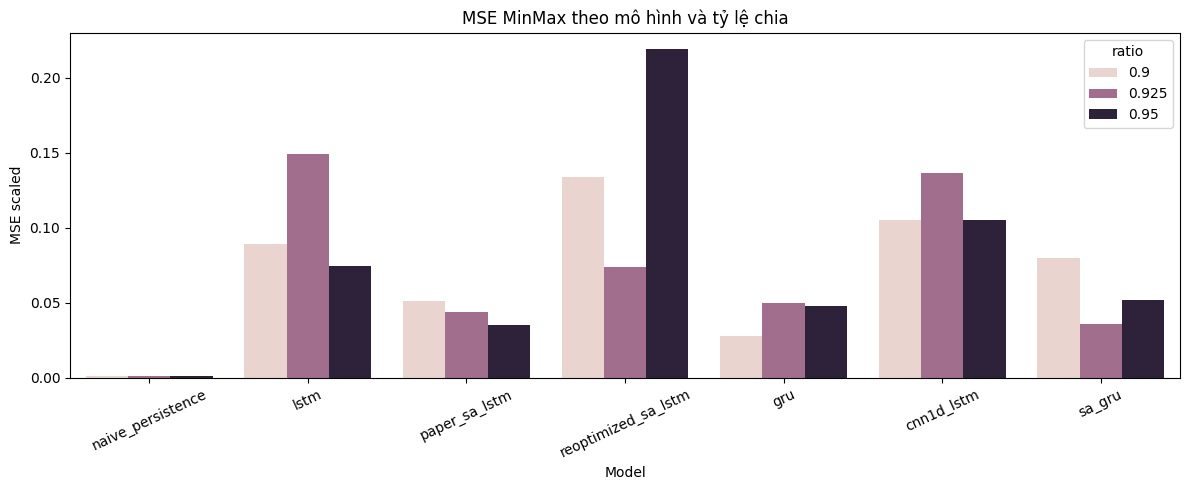

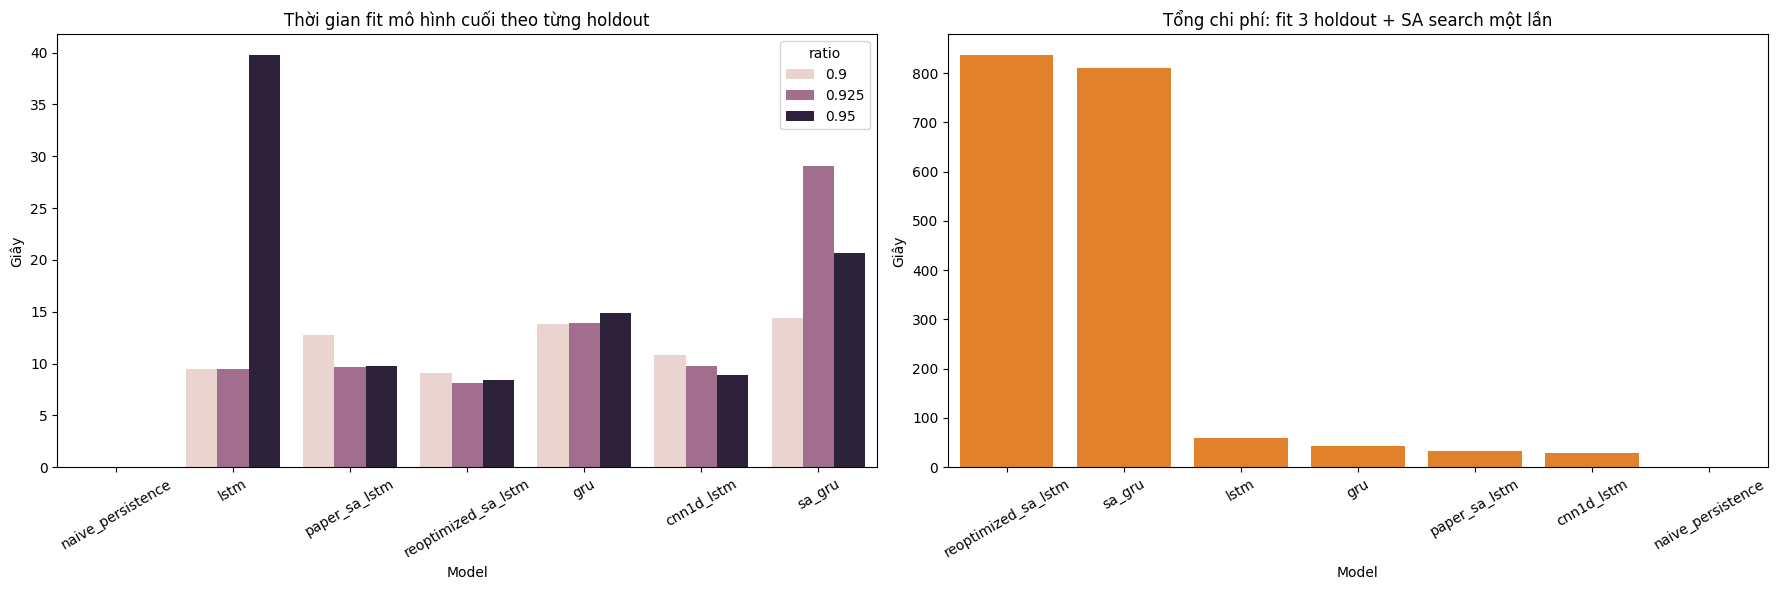

,ratio,model,mse_scaled,n_test,train_seconds
0,0.900,naive_persistence,0.001021,271,0.0
7,0.925,naive_persistence,0.000968,204,0.0
14,0.950,naive_persistence,0.000870,136,0.0


,model,mean_train_seconds,total_train_seconds_all_ratios,mean_seconds_per_epoch,total_prediction_seconds,one_time_sa_search_seconds,total_fit_plus_search_seconds,total_fit_plus_search_minutes
5,reoptimized_sa_lstm,8.523299,25.569898,0.502786,1.577855,811.066075,836.635973,13.943933
6,sa_gru,21.406958,64.220873,0.415102,1.489166,745.663136,809.884010,13.498067
2,lstm,19.570585,58.711756,0.462031,1.699854,0.000000,58.711756,0.978529
1,gru,14.214015,42.642044,0.439483,1.528391,0.000000,42.642044,0.710701
4,paper_sa_lstm,10.704375,32.113124,0.491559,1.599780,0.000000,32.113124,0.535219
0,cnn1d_lstm,9.818455,29.455366,0.546168,1.805046,0.000000,29.455366,0.490923
3,naive_persistence,0.000000,0.000000,0.000000,0.000026,0.000000,0.000000,0.000000


Hoàn tất. Artifacts: /kaggle/working/copper_contemporaneous_paper_sa


In [15]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=results_df, x='model', y='mse_scaled', hue='ratio', ax=ax)
ax.set(title='MSE MinMax theo mô hình và tỷ lệ chia', xlabel='Model', ylabel='MSE scaled')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'mse_scaled_comparison.png', dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.barplot(data=results_df, x='model', y='train_seconds', hue='ratio', ax=axes[0])
axes[0].set(title='Thời gian fit mô hình cuối theo từng holdout', xlabel='Model', ylabel='Giây')
axes[0].tick_params(axis='x', rotation=30)
time_order = time_summary.sort_values('total_fit_plus_search_seconds', ascending=False)
sns.barplot(data=time_order, x='model', y='total_fit_plus_search_seconds', color='tab:orange', ax=axes[1])
axes[1].set(title='Tổng chi phí: fit 3 holdout + SA search một lần', xlabel='Model', ylabel='Giây')
axes[1].tick_params(axis='x', rotation=30)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_time_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

best_by_ratio = results_df.loc[results_df.groupby('ratio')['mse_scaled'].idxmin()].sort_values('ratio')
display(best_by_ratio[['ratio', 'model', 'mse_scaled', 'n_test', 'train_seconds']])
display(time_summary)
print('Hoàn tất. Artifacts:', OUTPUT_DIR.resolve())

## 16. Actual vs Predicted của cả 7 phương pháp

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


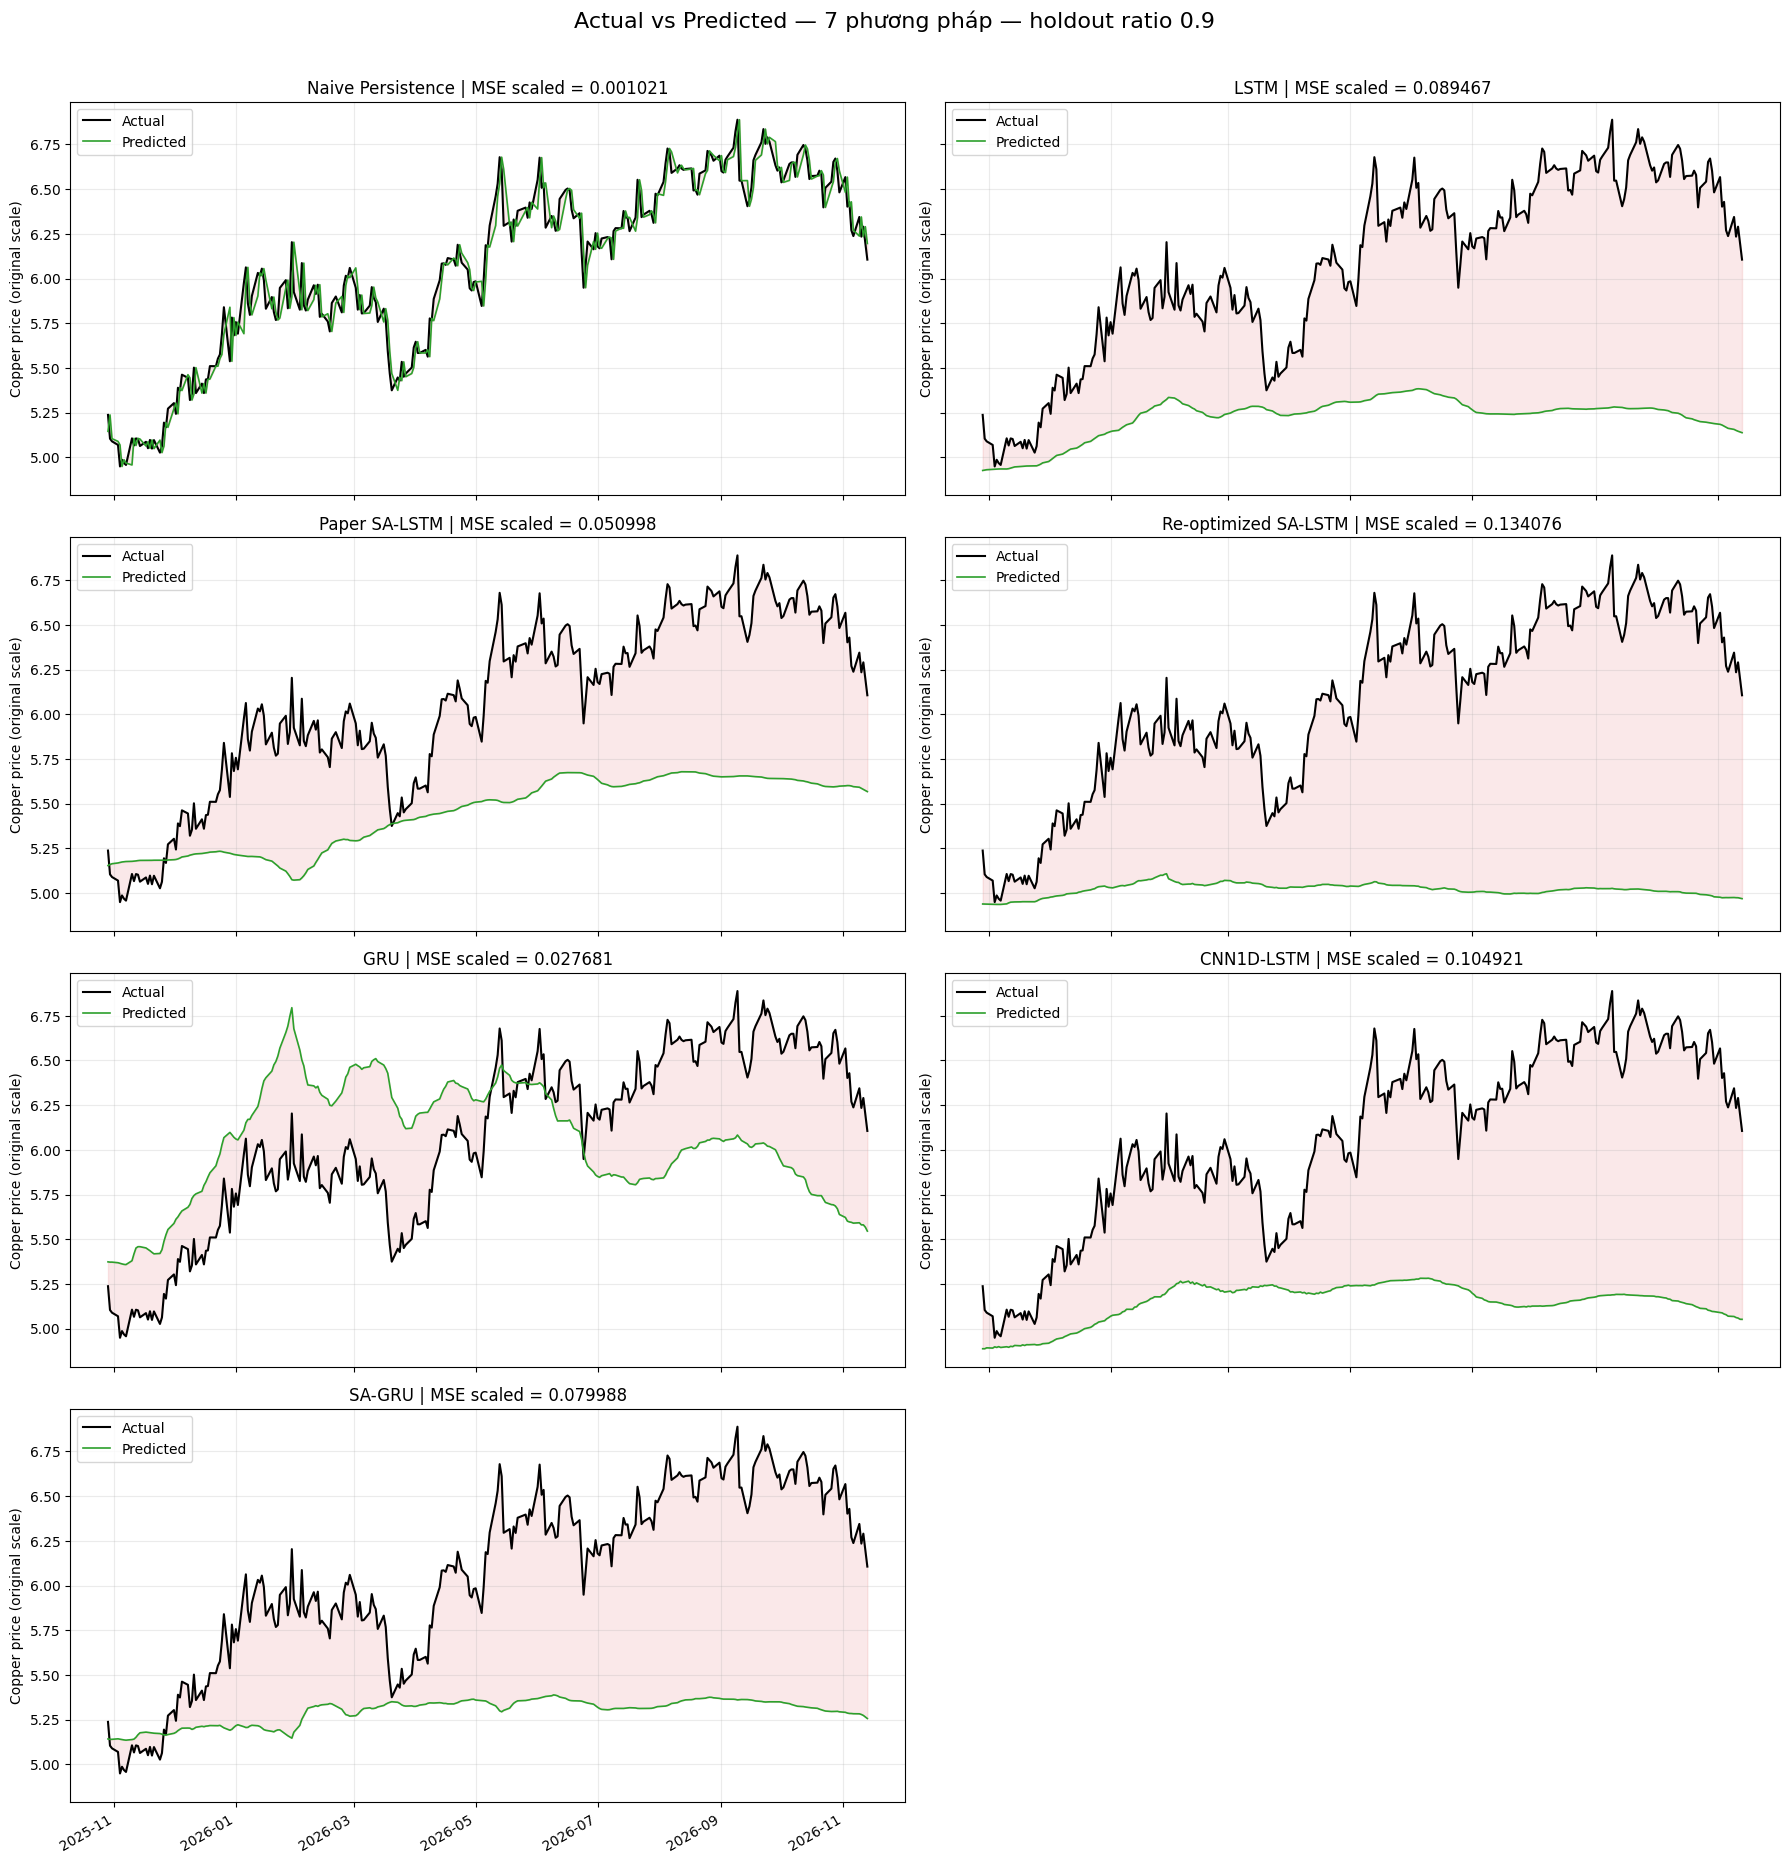

Đã lưu: /kaggle/working/copper_contemporaneous_paper_sa/actual_vs_predicted_7_models_0.9.png


In [16]:
# Chọn một holdout để quan sát: 0.90, 0.925 hoặc 0.95
PLOT_RATIO = 0.90
MODEL_ORDER = ['naive_persistence', 'lstm', 'paper_sa_lstm', 'reoptimized_sa_lstm', 'gru', 'cnn1d_lstm', 'sa_gru']
DISPLAY_NAMES = {
    'naive_persistence': 'Naive Persistence',
    'lstm': 'LSTM', 'paper_sa_lstm': 'Paper SA-LSTM',
    'reoptimized_sa_lstm': 'Re-optimized SA-LSTM', 'gru': 'GRU',
    'cnn1d_lstm': 'CNN1D-LSTM', 'sa_gru': 'SA-GRU',
}

plot_ctx = prepare_split(data, PLOT_RATIO)
plot_scaler = plot_ctx['y_scaler']
ncols = 2
nrows = math.ceil(len(MODEL_ORDER) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.6*nrows), sharex=True, sharey=True)
axes = axes.ravel()
reference_dates = None
reference_actual_scaled = None

for ax, model_name in zip(axes, MODEL_ORDER):
    prediction_path = OUTPUT_DIR / f'predictions_{model_name}_{PLOT_RATIO}.csv'
    if not prediction_path.is_file():
        raise FileNotFoundError(f'Chưa có {prediction_path.name}; hãy chạy cell benchmark trước.')
    frame = pd.read_csv(prediction_path, parse_dates=['Date'])
    actual_scaled = frame['actual_scaled'].to_numpy(dtype=float)
    predicted_scaled = frame['predicted_scaled'].to_numpy(dtype=float)
    if reference_dates is None:
        reference_dates = frame['Date'].to_numpy()
        reference_actual_scaled = actual_scaled.copy()
    else:
        if not np.array_equal(reference_dates, frame['Date'].to_numpy()):
            raise ValueError(f'Date không đồng nhất ở {model_name}')
        if not np.allclose(reference_actual_scaled, actual_scaled):
            raise ValueError(f'Actual không đồng nhất ở {model_name}')

    actual_price = plot_scaler.inverse_transform(actual_scaled.reshape(-1, 1)).ravel()
    predicted_price = plot_scaler.inverse_transform(predicted_scaled.reshape(-1, 1)).ravel()
    mse_scaled = mean_squared_error(actual_scaled, predicted_scaled)
    ax.plot(frame['Date'], actual_price, color='black', linewidth=1.5, label='Actual')
    ax.plot(frame['Date'], predicted_price, color='tab:green', linewidth=1.2, label='Predicted')
    ax.fill_between(frame['Date'], actual_price, predicted_price, color='tab:red', alpha=0.10)
    ax.set_title(f'{DISPLAY_NAMES[model_name]} | MSE scaled = {mse_scaled:.6f}')
    ax.set_ylabel('Copper price (original scale)')
    ax.grid(alpha=0.25)
    ax.legend(loc='best')

for unused_ax in axes[len(MODEL_ORDER):]:
    unused_ax.remove()
fig.suptitle(f'Actual vs Predicted — 7 phương pháp — holdout ratio {PLOT_RATIO}', fontsize=16, y=1.01)
fig.autofmt_xdate()
fig.tight_layout()
comparison_path = OUTPUT_DIR / f'actual_vs_predicted_7_models_{PLOT_RATIO}.png'
fig.savefig(comparison_path, dpi=180, bbox_inches='tight')
plt.show()
print('Đã lưu:', comparison_path.resolve())

In [19]:
from pathlib import Path
import os
import shutil
from IPython.display import FileLink, display

folder = Path("copper_contemporaneous_paper_sa")
working_dir = Path("/kaggle/working")
zip_name = "copper_contemporaneous_paper_sa.zip"
zip_path = working_dir / zip_name

if not folder.is_dir():
    raise FileNotFoundError(f"Không tìm thấy: {folder}")

# Tạo lại ZIP
shutil.make_archive(
    base_name=str(zip_path.with_suffix("")),
    format="zip",
    root_dir=str(folder)
)

if not zip_path.is_file():
    raise FileNotFoundError("Tạo ZIP thất bại")

print(f"Đã tạo: {zip_path}")
print(f"Kích thước: {zip_path.stat().st_size / 1024**2:.2f} MB")

# FileLink phải dùng đường dẫn tương đối
os.chdir("/kaggle/working")
display(FileLink(zip_name))

Đã tạo: /kaggle/working/copper_contemporaneous_paper_sa.zip
Kích thước: 3.36 MB


/kaggle/working/copper_contemporaneous_paper_sa.zip

## Ghi chú diễn giải

- Naive Persistence là baseline bổ sung, không phải phương pháp được khẳng định trong bài báo gốc.
- Paper SA-LSTM dùng trực tiếp 39/111 và LR=5e-5; không chạy lại SA để giả vờ tái tìm ra cấu hình đã công bố.
- Re-optimized SA-LSTM và SA-GRU thực hiện hai lần tìm kiếm độc lập trên validation MSE.
- `train_seconds` chỉ đo `model.fit()` của mô hình cuối; `prediction_seconds` đo suy luận. Chi phí SA được tách riêng thành `one_time_sa_search_seconds` để không cộng lặp ở ba holdout.
- Paper SA-LSTM dùng cấu hình đã công bố nên chi phí SA của tác giả không được tính vào runtime notebook hiện tại.
- Nếu mô hình học sâu không thắng Persistence, không được kết luận chỉ từ đường dự báo trông mượt hoặc đẹp.
- Bài toán dùng Price/closed của các biến tại ngày t để ước lượng Copper Price/closed tại t; đây là contemporaneous estimation, không phải forecast t+1.
- Top 4 được chọn theo `spearman_price` trên phân tích khám phá toàn giai đoạn; cell train-only Spearman giúp kiểm tra mức ổn định nhưng không xóa hoàn toàn rủi ro selection bias.